Решить задачу классификации изображений 
([https://disk.yandex.ru/d/ywO9_qnlDulNgQ](https://disk.yandex.ru/d/ywO9_qnlDulNgQ)). 

Метки по умолчанию — алфавитный порядок папок классов:   
(butterfly=0, cat=1, ...).

In [1]:
import logging
from datetime import datetime
from pathlib import Path
from typing import Final, Optional, TypedDict

import numpy as np
import matplotlib.pyplot as plt
import mlflow
import pandas as pd
import torch
from mlflow.models import infer_signature, ModelSignature
from mlflow.types.schema import Schema, TensorSpec
from sklearn.model_selection import train_test_split
from torch import cuda, nn, Tensor
from torch.utils.data import DataLoader, Dataset
from torchvision.transforms import v2
from torchcodec.decoders import decode_image

from utils import *


mlflow_logger = logging.getLogger("mlflow")
mlflow_logger.setLevel(logging.WARNING)

In [2]:
device = torch.device('cuda' if cuda.is_available() else 'cpu')
cpu_device = torch.device('cpu')
is_bf16_available = 'Да' if cuda.is_bf16_supported() else 'Нет'
print(f"Используем устройство {device}")
print(f"BF16 поддерживается: {is_bf16_available}")

Используем устройство cpu
BF16 поддерживается: Нет


In [3]:
class EpochTrainMetrics(TypedDict):
    """Метрики эпохи обучения на трейне."""
    train_loss: float
    train_accuracy: float


class EpochValMetrics(TypedDict):
    """Метрики эпохи обучения на валидации."""
    val_loss: float
    val_accuracy: float


class MlflowEpochMetrics(EpochTrainMetrics, EpochValMetrics):
    """Метрики эпохи, логирующиеся Mlflow."""
    pass


class AdamWConfig(TypedDict):
    """
    Типизирует гиперпараметры оптимизатора AdamW.

    Для использования в оптимизаторе - распаковать 
    объект через double star expression
    """
    lr: float


class HyperParams(TypedDict):
    """Гиперпараметры для логирования в Mlflow."""
    epochs: int
    learning_rate: float
    batch_size: int
    optimizer: str


def count_trainable_params(model: nn.Module) -> int:
    """Возвращает число обучаемых параметров модели."""
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

Напишем свой класс `AnimalDataset` для работы с датасетом через API PyTorch:

In [4]:
class AnimalDataset(Dataset):
    """
    Обертка над датасетом для его использования в обучении нейросетей на PyTorch.

    Parameters:
        label_map_file: Путь к файлу с парами 'класс,номер'
        img_dir: Путь к выборке
        transform: Аугментационный пайплайн
    """
    RESOLUTION = (320, 320)
    
    def __init__(self, annotations_file: Path, img_dir: Path, transform: Optional[v2.Compose] = None):
        self.img_labels = pd.read_csv(annotations_file)
        self.img_dir = img_dir
        self.transform = transform

        self.resizer = v2.Resize(self.RESOLUTION)

    def __len__(self) -> int:
        return len(self.img_labels)

    def __getitem__(self, idx: int) -> tuple[Tensor, str]:
        img_path = Path(self.img_labels.iloc[idx, 0])
        image = decode_image(img_path) / 255.0
        image = self.resizer(image)
        if self.transform is not None:
            image = self.transform(image)
        label = self.img_labels.iloc[idx, 1]
        return image, label


class SubmitDataset(Dataset):
    """
    Обертка над данными для сабмита.

    Parameters:
        submission_example_file: Путь к примеру сабмита
        img_dir: Путь к тестовой выборке
    """
    RESOLUTION = (320, 320)
    
    def __init__(self, submission_example_file: Path, img_dir: Path):
        df = pd.read_csv(submission_example_file)
        self.image_files = tuple(f for f in df.FILE_NAME)
        self.img_dir = img_dir

        self.resizer = v2.Resize(self.RESOLUTION)

    def __len__(self) -> int:
        return len(self.image_files)

    def __getitem__(self, idx: int) -> tuple[str, Tensor]:
        img_path = Path(self.img_dir / self.image_files[idx])
        image = decode_image(img_path) / 255.0
        image = self.resizer(image)
        img_name = img_path.name  # Требование шаблона для сабмита
        return img_name, image

# Подготовка датасета

In [5]:
def prepare_dataset(label_map_path: Path, img_dir: Path) -> pd.DataFrame:
    """
    Собирает DataFrame с лейблами изображений.

    Parameters:
        label_map_path: Путь к .csv-файлу с парами 'класс,номер'
        img_dir: Путь к датасету со структурой 'класс/изображения-класса'
    """
    label_map = pd.read_csv(
        label_map_path,
        index_col="name"
    )['target'].to_dict()
    images = pd.DataFrame([
        (file, label_map[class_dir.name])
        for class_dir in img_dir.iterdir()
        if class_dir.is_dir()
        for file in class_dir.iterdir()
        if file.is_file()
    ], columns=['Path', 'Target'])
    return images

In [6]:
dataset_labels_path = get_dataset_labels_path()
if not dataset_labels_path.exists():
    labels = prepare_dataset(get_label_map_path(), get_dataset_data_path())
    labels.to_csv(dataset_markup_path, index=None)

Разобьем обучающую выборку на обучающую и тестовую (валидационную) выборки в соотношении $7:3$:

In [7]:
dataset = pd.read_csv(get_dataset_labels_path())
dataset.head(3)

,Path,Target
0,dataset\train\butterfly\e030b20928e90021d85a58...,0
1,dataset\train\butterfly\e030b20929e90021d85a58...,0
2,dataset\train\butterfly\e030b2092be90021d85a58...,0


In [8]:
X, y = dataset.Path, dataset.Target

X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, train_size=0.7, stratify=y, random_state=42
)
print(f"Размер train: {len(X_train)}")
print(f"Размер valid: {len(X_valid)}")
pd.concat([X_train, y_train], axis=1).to_csv(get_train_labels_path(), index=False)
pd.concat([X_valid, y_valid], axis=1).to_csv(get_val_labels_path(), index=False)

Размер train: 12291
Размер valid: 5268


## Просмотр изображения из датасета

Отрисуем изображение из датасета:

In [9]:
class AnimalLabels:
    def __init__(self, label_map_path: Path):
        self.name_map = pd.read_csv(label_map_path, index_col="name").to_dict()['target']
        self.target_map = pd.read_csv(label_map_path, index_col="target").to_dict()['name']

    def get_name(self, target: int) -> str:
        return self.target_map[target]

    def get_target(self, name: str) -> int:
        return self.name_map[name]

torch.Size([3, 320, 320])


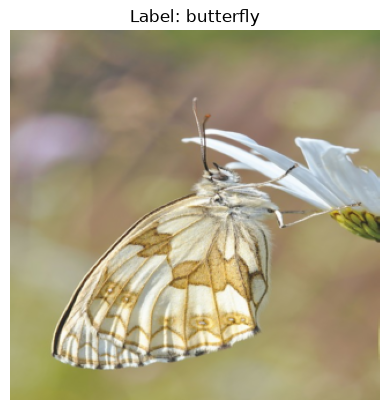

In [10]:
animal_labels = AnimalLabels(get_label_map_path())
clear_train_data = AnimalDataset(get_dataset_labels_path(), get_dataset_data_path())
clear_train_dataloader = DataLoader(clear_train_data, shuffle=False)


img, label = clear_train_dataloader.dataset[0]
print(img.shape)
plt.imshow(img.squeeze().permute(1, 2, 0))
plt.axis("off")
plt.title(f"Label: {animal_labels.get_name(label)}")
plt.show()

# Обучение модели

In [11]:
BATCH_SIZE: Final = 16

train_transform = v2.Compose([
    v2.RandomHorizontalFlip(p=0.5),
    v2.RandomRotation(10),
    v2.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.1),
    v2.RandomErasing(p=0.2, scale=(0.02, 0.2), value='random'),
])
training_data = AnimalDataset(get_train_labels_path(), get_dataset_data_path(), train_transform)
train_dataloader = DataLoader(training_data, batch_size=BATCH_SIZE, shuffle=True)
validating_data = AnimalDataset(get_val_labels_path(), get_dataset_data_path())
val_dataloader = DataLoader(validating_data, batch_size=BATCH_SIZE, shuffle=True)

Напишем цикл обучения и цикл валидации:

In [12]:
def train_loop(dataloader: DataLoader, model: nn.Module, loss_fn, optimizer, device) -> EpochTrainMetrics:
    model.train()
    size = len(dataloader.dataset)
    num_batches = len(dataloader)
    train_loss = 0.0
    correct = 0
    
    for batch_idx, (X, y) in enumerate(dataloader):
        X, y = X.to(device), y.to(device)
        batch_size = X.size(0)
        pred = model(X)
        loss = loss_fn(pred, y)
        
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()

        train_loss += loss.item() * batch_size
        correct += (pred.argmax(1) == y).sum().item()

    epoch_loss = train_loss / num_batches
    epoch_acc = correct / size
    return EpochTrainMetrics(
        train_loss=epoch_loss,
        train_accuracy=epoch_acc
    )


def val_loop(dataloader: DataLoader, model: nn.Module, loss_fn, device) -> EpochValMetrics:
    model.eval()
    size = len(dataloader.dataset)
    num_batches = len(dataloader)
    val_loss = 0.0
    correct = 0
    
    with torch.no_grad():
        for X, y in dataloader:
            X, y = X.to(device), y.to(device)
            pred = model(X)
            val_loss += loss_fn(pred, y).item()
            correct += (pred.argmax(1) == y).sum().item()

    val_loss /= num_batches
    val_acc = correct / size
    return EpochValMetrics(
        val_loss=val_loss,
        val_accuracy=val_acc
    )

Объявляем архитектуру нашей CNN:

In [13]:
class ResConv(nn.Module):
    def __init__(self, in_channels: int, out_channels: int, stride: int = 1, **kwargs):
        super().__init__()
        self.main = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, stride=stride, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, stride=1, padding=1, bias=False),
            nn.BatchNorm2d(out_channels)
        )
        self.shortcut = nn.Identity()
        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_channels, out_channels, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm2d(out_channels)
            )
        self.activation = nn.ReLU(inplace=True)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.activation(self.main(x) + self.shortcut(x))


model = nn.Sequential(
    # Stem 
    nn.Conv2d(3, 24, kernel_size=3, padding=1, bias=False),
    nn.BatchNorm2d(24),
    nn.ReLU(inplace=True),
    # Features
    ResConv(24, 48),
    nn.MaxPool2d(2),
    ResConv(48, 96),
    nn.MaxPool2d(2),
    ResConv(96, 192),
    nn.MaxPool2d(2),
    ResConv(192, 256),
    # Head
    nn.AdaptiveAvgPool2d(1),
    nn.Flatten(),
    nn.Dropout(0.1),
    nn.Linear(256, 10)
).to(device)
trainable_params = count_trainable_params(model)
print(f"Количество обучаемых параметров: {trainable_params}")

Количество обучаемых параметров: 1765538


Обсчитываем сигнатуру входных и выходных данных модели:

In [14]:
input_example = torch.zeros(2, 3, 320, 320).to(device)
input_schema = Schema([TensorSpec(np.dtype(np.float32), (-1, 3, 320, 320))])
output_schema = Schema([TensorSpec(np.dtype(np.float32), (-1, 10))])
signature = ModelSignature(inputs=input_schema, outputs=output_schema)

mlflow.set_tracking_uri("http://localhost:5000")
mlflow.set_experiment("DL_LW01")
mlflow.config.enable_system_metrics_logging()
mlflow.config.set_system_metrics_sampling_interval(1)

Запускаем цикл обучения:

In [ ]:
EPOCHS: Final = 150

loss_fn = nn.CrossEntropyLoss()
optimizer_config = AdamWConfig(lr=1e-4)
optimizer = torch.optim.AdamW(model.parameters(), **optimizer_config)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

params = HyperParams(
    epochs=EPOCHS,
    learning_rate=optimizer_config["lr"],
    batch_size=BATCH_SIZE,
    optimizer="AdamW",
)

In [18]:
dt_now = datetime.now().strftime("%Y-%m-%d %H:%M:%S")
with mlflow.start_run(run_name=dt_now) as run:
    try: 
        mlflow.log_params(params)
        for epoch in range(EPOCHS):
            print(f"Epoch {epoch}: Training...")
            train_metrics = train_loop(train_dataloader, model, loss_fn, optimizer, device)
            print(f"Epoch {epoch}: Validating...")
            val_metrics = val_loop(val_dataloader, model, loss_fn, device)
            scheduler.step()
    
            mlflow.log_metrics(
                MlflowEpochMetrics(**train_metrics, **val_metrics),
                step=epoch
            )

        model_name = "final_model"
        print("Done!")
        
    except KeyboardInterrupt:
        model_name = "manual_interrupt"
        print("Обучение прервано :(")
        
    finally:
        model.cpu()
        model_info = mlflow.pytorch.log_model(
            model, 
            input_example=input_example,
            signature=signature, 
            name="final_model"
        )
        model.to(device)
        torch.save(model.state_dict(), get_weights_path() / f'model_{dt_now}.pth')

Epoch 0: Training...
Epoch 0: Validating...
Epoch 1: Training...
Epoch 1: Validating...
Epoch 2: Training...
Epoch 2: Validating...
Epoch 3: Training...
Epoch 3: Validating...
Epoch 4: Training...
Epoch 4: Validating...
Epoch 5: Training...
Epoch 5: Validating...
Epoch 6: Training...
Epoch 6: Validating...
Epoch 7: Training...
Epoch 7: Validating...
Epoch 8: Training...
Epoch 8: Validating...
Epoch 9: Training...
Epoch 9: Validating...
Epoch 10: Training...
Epoch 10: Validating...
Epoch 11: Training...
Epoch 11: Validating...
Epoch 12: Training...
Epoch 12: Validating...
Epoch 13: Training...
Epoch 13: Validating...
Epoch 14: Training...
Epoch 14: Validating...
Epoch 15: Training...
Epoch 15: Validating...
Epoch 16: Training...
Epoch 16: Validating...
Epoch 17: Training...
Epoch 17: Validating...
Epoch 18: Training...
Epoch 18: Validating...
Epoch 19: Training...
Epoch 19: Validating...
Epoch 20: Training...
Epoch 20: Validating...
Epoch 21: Training...
Epoch 21: Validating...
Epoch 22

2026/11/24 22:06:46 WARNING mlflow.utils.requirements_utils: Found torch version (2.15.0+cu132) contains a local version label (+cu132). MLflow logged a pip requirement for this package as 'torch==2.15.0' without the local version label to make it installable from PyPI. To specify pip requirements containing local version labels, please use `conda_env` or `pip_requirements`.
2026/11/24 22:06:46 WARNING mlflow.utils.uv_utils: Private package indexes detected in uv lockfile. Ensure credentials are available at model load time via UV_INDEX_* environment variables or .netrc file.
2026/11/24 22:06:46 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


🏃 View run 2026-11-24 21:02:15 at: http://localhost:5000/#/experiments/2/runs/5803d0eb41d84bb8920684392d2b8d41
🧪 View experiment at: http://localhost:5000/#/experiments/2


In [18]:
model_uri = "models:/m-3164222f515f40d9a46fd9acafb22ba9/"
model = mlflow.pytorch.load_model(model_uri)
submit_dataset = SubmitDataset('submission_dl1.csv', get_submit_data_path())
submit_dataloader = DataLoader(submit_dataset, shuffle=False)

model.eval()
with torch.no_grad():
    with open("submit.csv", "w", encoding="utf-8") as submit_file:
        submit_file.write("FILE_NAME,TARGET\n")
        for img_names, images in submit_dataloader:
            images = images.to(device)
            pred = model(images).argmax(1).item()
            img_name = img_names[0]
            submit_file.write(f"{img_name},{pred}\n")

2026/11/25 16:41:56 WARNING mlflow.pytorch: Stored model version '2.15.0+cu132' does not match installed PyTorch version '2.15.0+cpu'


AssertionError: Torch not compiled with CUDA enabled